# Scattering From a Conducting Sphere: The Mie Series

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jman4162/RF-and-Antenna-Tutorials/blob/main/Scattering_From_a_Conducting_Sphere_Mie_Series_Tutorial.ipynb)

This notebook solves plane-wave scattering by a perfectly conducting (PEC) sphere with a multipole expansion in vector spherical harmonics, the classical Mie solution. It checks the expansion, the boundary condition and the optical theorem directly, reproduces the textbook radar cross-section (RCS) curve, and then maps the total field for the configuration of a Virginia Tech ECE 5106 homework set (spring 2016): $k = 1$ m$^{-1}$ and sphere radius $a = 0.6$ m, so $ka = 0.6$. The original MATLAB is in [electromagnetics-work-samples](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/multipole-scattering).

Topics:

- Spherical Bessel and Hankel functions and the Riccati-Bessel functions $\psi_n$ and $\xi_n$
- The expansion of a plane wave in vector spherical harmonics
- Mie coefficients for a PEC sphere
- Scattering, extinction and backscatter cross sections, and the optical theorem
- The Rayleigh, resonance and optical regions of the RCS curve
- Near-field maps, with a direct check that the tangential electric field vanishes on the sphere

## Conventions

This notebook follows Bohren and Huffman (1983), chapter 4: time dependence $e^{-i\omega t}$, outgoing waves described by $h_n^{(1)}$, and an incident wave $\mathbf{E}_i = E_0\,e^{ikz}\,\hat{\mathbf{x}}$. Texts that use $e^{+j\omega t}$ with $h_n^{(2)}$ (Harrington, Balanis) give complex conjugates of the field coefficients; every cross section is the same.

## Theory

With $\rho = kr$, $\mu = \cos\theta$, and $z_n$ standing for $j_n$ (incident, regular at the origin) or $h_n^{(1)}$ (scattered, outgoing), the vector spherical harmonics needed for an $x$-polarized wave are

$$\mathbf{M}_{o1n} = \cos\phi\,\pi_n z_n\,\hat{\boldsymbol\theta} - \sin\phi\,\tau_n z_n\,\hat{\boldsymbol\phi},$$
$$\mathbf{N}_{e1n} = \cos\phi\; n(n+1)\sin\theta\,\pi_n \frac{z_n}{\rho}\,\hat{\mathbf r} + \cos\phi\,\tau_n \frac{[\rho z_n]'}{\rho}\,\hat{\boldsymbol\theta} - \sin\phi\,\pi_n\frac{[\rho z_n]'}{\rho}\,\hat{\boldsymbol\phi},$$

where the angular functions follow the recurrences $\pi_0 = 0$, $\pi_1 = 1$, $\pi_n = \frac{2n-1}{n-1}\mu\pi_{n-1} - \frac{n}{n-1}\pi_{n-2}$ and $\tau_n = n\mu\pi_n - (n+1)\pi_{n-1}$.

The incident and scattered fields are

$$\mathbf{E}_i = \sum_{n=1}^\infty E_n\left(\mathbf{M}^{(1)}_{o1n} - i\,\mathbf{N}^{(1)}_{e1n}\right), \qquad \mathbf{E}_s = \sum_{n=1}^\infty E_n\left(i a_n \mathbf{N}^{(3)}_{e1n} - b_n \mathbf{M}^{(3)}_{o1n}\right), \qquad E_n = i^n E_0 \frac{2n+1}{n(n+1)} .$$

Requiring the tangential total field to vanish at $r = a$ gives the PEC Mie coefficients, with $x = ka$, $\psi_n(x) = x j_n(x)$ and $\xi_n(x) = x h_n^{(1)}(x)$:

$$a_n = \frac{\psi_n'(x)}{\xi_n'(x)}, \qquad b_n = \frac{\psi_n(x)}{\xi_n(x)} .$$

The cross sections, normalized by the geometric area $\pi a^2$, are

$$Q_{\mathrm{sca}} = \frac{2}{x^2}\sum_n (2n+1)\left(|a_n|^2 + |b_n|^2\right), \quad Q_{\mathrm{ext}} = \frac{2}{x^2}\sum_n (2n+1)\,\mathrm{Re}(a_n + b_n), \quad Q_{\mathrm{b}} = \frac{1}{x^2}\left|\sum_n (2n+1)(-1)^n (a_n - b_n)\right|^2 .$$

$Q_{\mathrm{b}}\,\pi a^2$ is the monostatic RCS $\sigma_b$. The series is truncated at $n_{\max} = x + 4x^{1/3} + 2$ (Wiscombe, 1980), using the largest $kr$ in a near-field map instead of $x$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import spherical_jn, spherical_yn

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

In [2]:
def n_max(x):
    return int(np.ceil(x + 4 * x ** (1 / 3) + 2))


def pec_mie_coefficients(x, nmax=None):
    """Mie coefficients a_n, b_n (Bohren & Huffman) of a PEC sphere with size parameter x = ka."""
    n = np.arange(1, (nmax or n_max(x)) + 1)
    j, jp = spherical_jn(n, x), spherical_jn(n, x, derivative=True)
    h, hp = j + 1j * spherical_yn(n, x), jp + 1j * spherical_yn(n, x, derivative=True)
    psi, dpsi = x * j, j + x * jp
    xi, dxi = x * h, h + x * hp
    return n, dpsi / dxi, psi / xi


def efficiencies(x):
    """Normalized scattering, extinction and backscatter cross sections Q = sigma / (pi a^2)."""
    n, a, b = pec_mie_coefficients(x)
    q_sca = 2 / x**2 * np.sum((2 * n + 1) * (abs(a) ** 2 + abs(b) ** 2))
    q_ext = 2 / x**2 * np.sum((2 * n + 1) * (a + b).real)
    q_b = abs(np.sum((2 * n + 1) * (-1) ** n * (a - b))) ** 2 / x**2
    return q_sca, q_ext, q_b


def pi_tau(theta, nmax):
    mu = np.cos(theta)
    pi = np.zeros((nmax + 1,) + np.shape(theta))
    tau = np.zeros_like(pi)
    pi[1] = 1.0
    for n in range(2, nmax + 1):
        pi[n] = (2 * n - 1) / (n - 1) * mu * pi[n - 1] - n / (n - 1) * pi[n - 2]
    for n in range(1, nmax + 1):
        tau[n] = n * mu * pi[n] - (n + 1) * pi[n - 1]
    return pi[1:], tau[1:]


def fields(r, theta, phi, k, a, E0=1.0, which="total", nmax=None):
    """(E_r, E_theta, E_phi) at points (r, theta, phi) for an x-polarized plane wave on a PEC sphere."""
    r, theta, phi = (np.atleast_1d(np.asarray(v, dtype=float)) for v in (r, theta, phi))
    x = k * a
    nmax = nmax or max(n_max(k * r.max()), n_max(x))
    n = np.arange(1, nmax + 1)[:, None]
    _, an, bn = pec_mie_coefficients(x, nmax)
    an, bn = an[:, None], bn[:, None]
    rho = (k * r)[None, :]
    th, ph = theta[None, :], phi[None, :]
    pi, tau = pi_tau(theta, nmax)
    En = (1j**n) * E0 * (2 * n + 1) / (n * (n + 1))

    def harmonics(z, zp):
        dz = (z + rho * zp) / rho                          # [rho z_n]' / rho
        M = (0 * z, np.cos(ph) * pi * z, -np.sin(ph) * tau * z)
        N = (np.cos(ph) * n * (n + 1) * np.sin(th) * pi * z / rho, np.cos(ph) * tau * dz, -np.sin(ph) * pi * dz)
        return M, N

    j, jp = spherical_jn(n, rho), spherical_jn(n, rho, derivative=True)
    h, hp = j + 1j * spherical_yn(n, rho), jp + 1j * spherical_yn(n, rho, derivative=True)
    M1, N1 = harmonics(j, jp)
    M3, N3 = harmonics(h, hp)
    Ei = [np.sum(En * (M1[c] - 1j * N1[c]), axis=0) for c in range(3)]
    Es = [np.sum(En * (1j * an * N3[c] - bn * M3[c]), axis=0) for c in range(3)]
    if which == "incident":
        return Ei
    if which == "scattered":
        return Es
    return [Ei[c] + Es[c] for c in range(3)]

## Checks

1. The incident series reproduces $e^{ikz}\hat{\mathbf{x}}$ at random points (this is homework problem 4: the plane-wave expansion).
2. The tangential total field vanishes on the sphere surface, which is the PEC boundary condition the coefficients were derived from.
3. The optical theorem: a lossless sphere absorbs nothing, so $Q_{\mathrm{ext}} = Q_{\mathrm{sca}}$ for every size.
4. Rayleigh limit ($x \ll 1$): $Q_{\mathrm{sca}} \to \tfrac{10}{3}x^4$ and $Q_{\mathrm{b}} \to 9x^4$.
5. Optical limit ($x \gg 1$): $Q_{\mathrm{b}} \to 1$ (the specular return of a sphere is $\pi a^2$) and $Q_{\mathrm{ext}} \to 2$ (the extinction paradox).

In [3]:
rng = np.random.default_rng(0)

# 1. Plane-wave expansion
r, th, ph = rng.uniform(0.1, 3, 200), rng.uniform(0.01, np.pi - 0.01, 200), rng.uniform(0, 2 * np.pi, 200)
Er, Et, Ep = fields(r, th, ph, k=1.0, a=0.6, which="incident", nmax=40)
plane = np.exp(1j * r * np.cos(th))                          # e^{ikz}, k = 1
x_hat = (np.sin(th) * np.cos(ph), np.cos(th) * np.cos(ph), -np.sin(ph))
err_inc = max(np.max(np.abs(E - plane * u)) for E, u in zip((Er, Et, Ep), x_hat))
assert err_inc < 1e-12

# 2. PEC boundary condition at r = a
th, ph = rng.uniform(0.01, np.pi - 0.01, 200), rng.uniform(0, 2 * np.pi, 200)
Er, Et, Ep = fields(np.full(200, 0.6), th, ph, k=1.0, a=0.6)
e_tan = np.max(np.abs(np.r_[Et, Ep]))
assert e_tan < 1e-12 * np.max(np.abs(Er))

# 3-5. Optical theorem and the two limits
xs = np.logspace(-2, 2, 60)
Q = np.array([efficiencies(x) for x in xs])
assert np.max(np.abs(Q[:, 1] - Q[:, 0]) / Q[:, 0]) < 1e-12
q_sca, _, q_b = efficiencies(0.01)
assert abs(q_sca / (10 / 3 * 0.01**4) - 1) < 1e-3 and abs(q_b / (9 * 0.01**4) - 1) < 1e-3
_, q_ext, q_b = efficiencies(100.0)
assert abs(q_b - 1) < 0.01 and abs(q_ext - 2) < 0.01

print(f"1. Incident expansion, max error: {err_inc:.1e}")
print(f"2. Max tangential E on the sphere: {e_tan:.1e} (max normal E: {np.max(np.abs(Er)):.2f})")
print(f"3. Max |Q_ext - Q_sca| / Q_sca for 0.01 <= ka <= 100: {np.max(np.abs(Q[:, 1] - Q[:, 0]) / Q[:, 0]):.1e}")
print(f"4. ka = 0.01: Q_sca / (10/3 x^4) = {efficiencies(0.01)[0] / (10 / 3 * 1e-8):.5f}, Q_b / (9 x^4) = {efficiencies(0.01)[2] / 9e-8:.5f}")
print(f"5. ka = 100: Q_b = {q_b:.4f}, Q_ext = {q_ext:.4f}")
print("All checks passed.")

1. Incident expansion, max error: 1.6e-15
2. Max tangential E on the sphere: 4.5e-16 (max normal E: 3.50)
3. Max |Q_ext - Q_sca| / Q_sca for 0.01 <= ka <= 100: 5.2e-16
4. ka = 0.01: Q_sca / (10/3 x^4) = 1.00002, Q_b / (9 x^4) = 0.99998
5. ka = 100: Q_b = 0.9990, Q_ext = 2.0081
All checks passed.


## The radar cross section of a sphere

The normalized monostatic RCS $\sigma_b/\pi a^2$ is the classic calibration curve for radar ranges. It rises as $9(ka)^4$ in the Rayleigh region, oscillates in the resonance region as the specular return interferes with a creeping wave that travels around the shadow side, and settles to 1 in the optical region.

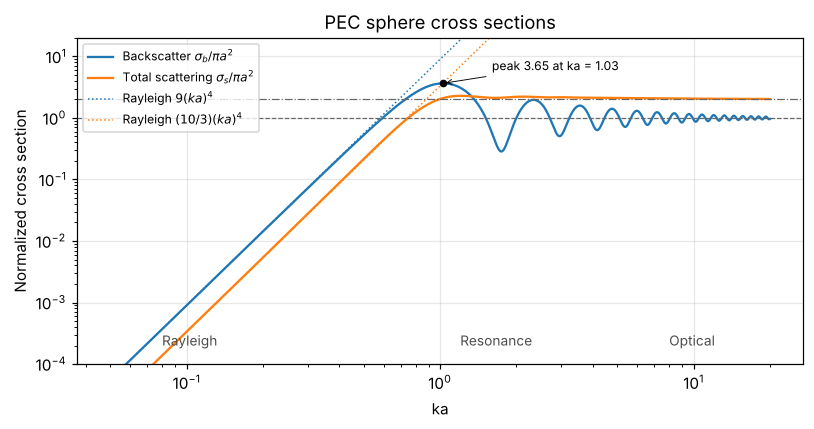

In [4]:
ka = np.logspace(np.log10(0.05), np.log10(20), 1500)
Q = np.array([efficiencies(x) for x in ka])
peak = np.argmax(Q[:, 2] * (ka < 3))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.loglog(ka, Q[:, 2], "C0", label="Backscatter $\\sigma_b / \\pi a^2$")
ax.loglog(ka, Q[:, 0], "C1", label="Total scattering $\\sigma_s / \\pi a^2$")
ax.loglog(ka, 9 * ka**4, "C0:", lw=1, label="Rayleigh $9(ka)^4$")
ax.loglog(ka, 10 / 3 * ka**4, "C1:", lw=1, label="Rayleigh $(10/3)(ka)^4$")
ax.axhline(1, color="0.4", lw=0.8, ls="--")
ax.axhline(2, color="0.4", lw=0.8, ls="-.")
ax.plot(ka[peak], Q[peak, 2], "ko", ms=4)
ax.annotate(f"peak {Q[peak, 2]:.2f} at ka = {ka[peak]:.2f}", (ka[peak], Q[peak, 2]), xytext=(1.6, 6), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.6))
for x0, txt in [(0.08, "Rayleigh"), (1.2, "Resonance"), (8, "Optical")]:
    ax.text(x0, 2e-4, txt, fontsize=9, color="0.3")
ax.set(xlabel="ka", ylabel="Normalized cross section", ylim=(1e-4, 20), title="PEC sphere cross sections")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## Bistatic scattering patterns

The far-field amplitudes $S_1(\theta) = \sum_n \frac{2n+1}{n(n+1)}(a_n\pi_n + b_n\tau_n)$ and $S_2(\theta) = \sum_n \frac{2n+1}{n(n+1)}(a_n\tau_n + b_n\pi_n)$ give the bistatic RCS in the E-plane ($\phi = 0$, using $S_2$) and the H-plane ($\phi = 90°$, using $S_1$): $\sigma(\theta) = 4\pi|S|^2/k^2$. Two consistency checks tie them to the efficiencies above: the backscatter value $\sigma(\pi)$ must equal $\pi a^2 Q_{\mathrm{b}}$, and the forward amplitude must satisfy the optical theorem $Q_{\mathrm{ext}} = 4\,\mathrm{Re}\,S(0)/x^2$.

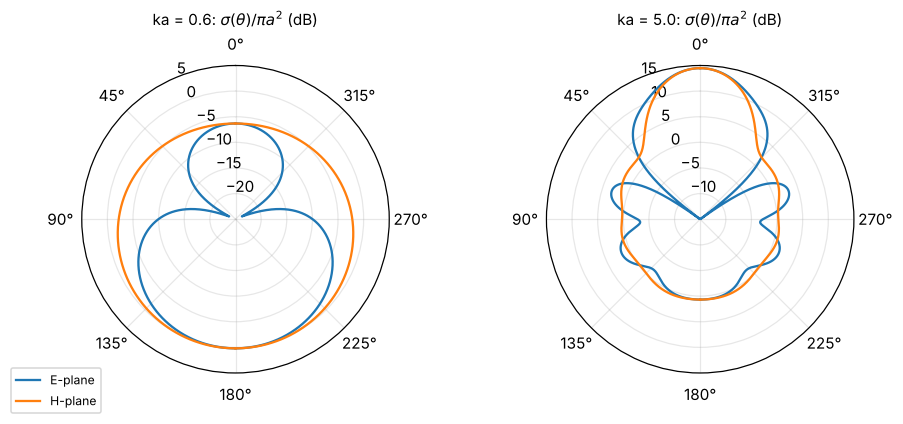

Backscatter and forward-scatter consistency checks passed for ka = 0.6 and ka = 5.


In [5]:
def amplitudes(x, theta):
    n, a, b = pec_mie_coefficients(x)
    pi, tau = pi_tau(np.atleast_1d(theta), len(n))
    c = ((2 * n + 1) / (n * (n + 1)))[:, None]
    S1 = np.sum(c * (a[:, None] * pi + b[:, None] * tau), axis=0)
    S2 = np.sum(c * (a[:, None] * tau + b[:, None] * pi), axis=0)
    return S1, S2

theta = np.linspace(0, np.pi, 721)
fig, axes = plt.subplots(1, 2, subplot_kw={"projection": "polar"}, figsize=(9, 4))
for ax, x in zip(axes, [0.6, 5.0]):
    S1, S2 = amplitudes(x, theta)
    q_sca, q_ext, q_b = efficiencies(x)
    sigma_E = 4 * np.abs(S2) ** 2 / x**2              # sigma / (pi a^2), E-plane
    sigma_H = 4 * np.abs(S1) ** 2 / x**2              # sigma / (pi a^2), H-plane
    assert abs(sigma_E[-1] / q_b - 1) < 1e-10 and abs(sigma_H[-1] / q_b - 1) < 1e-10
    assert abs(4 * S1[0].real / x**2 / q_ext - 1) < 1e-10
    db_E, db_H = 10 * np.log10(sigma_E), 10 * np.log10(sigma_H)
    top = np.ceil(max(db_E.max(), db_H.max()) / 5) * 5
    for db, lab, color in [(db_E, "E-plane", "C0"), (db_H, "H-plane", "C1")]:
        db = np.maximum(db, top - 30)                    # clip to the plotted dynamic range
        ax.plot(theta, db, color=color, label=lab)
        ax.plot(-theta, db, color=color)                 # mirror image: the pattern is symmetric
    ax.set_theta_zero_location("N")                      # forward scattering (theta = 0) at the top
    ax.set_title(f"ka = {x}: $\\sigma(\\theta)/\\pi a^2$ (dB)", fontsize=10)
    ax.set_rlim(top - 30, top)
axes[0].legend(fontsize=8, loc="lower left", bbox_to_anchor=(-0.25, -0.15))
plt.tight_layout()
plt.show()
print("Backscatter and forward-scatter consistency checks passed for ka = 0.6 and ka = 5.")

## The homework configuration: $k = 1$ m$^{-1}$, $a = 0.6$ m

The homework wrote the scattered field with coefficients $\alpha_L = -2j_L(ka)/h_L^{(1)}(ka)$ and $\beta_L = -2[x j_L]'/[x h_L^{(1)}]'$ at $x = ka$, and the scattering cross section as $\sigma_s = \frac{\pi}{2k^2}\sum_L (2L+1)(|\alpha_L|^2 + |\beta_L|^2)$. Since $\alpha_L = -2b_L$ and $\beta_L = -2a_L$, this is the same formula as $Q_{\mathrm{sca}}\,\pi a^2$ above. The cell below confirms it and shows how fast the series converges at $ka = 0.6$.

In [6]:
k_hw, a_hw = 1.0, 0.6
n, an, bn = pec_mie_coefficients(k_hw * a_hw, nmax=6)
alpha_L, beta_L = -2 * bn, -2 * an
terms = (2 * n + 1) * (np.abs(alpha_L) ** 2 + np.abs(beta_L) ** 2)
sigma_hw = np.pi / (2 * k_hw**2) * terms.sum()
sigma_mie = efficiencies(k_hw * a_hw)[0] * np.pi * a_hw**2
assert abs(sigma_hw / sigma_mie - 1) < 1e-9

for L, t in zip(n, terms):
    print(f"L = {L}: (2L+1)(|alpha|^2 + |beta|^2) = {t:.3e}")
print(f"sigma_s (homework formula, L <= 6) = {sigma_hw:.6f} m^2;  Mie series = {sigma_mie:.6f} m^2")

L = 1: (2L+1)(|alpha|^2 + |beta|^2) = 3.218e-01
L = 2: (2L+1)(|alpha|^2 + |beta|^2) = 1.744e-04
L = 3: (2L+1)(|alpha|^2 + |beta|^2) = 2.237e-08
L = 4: (2L+1)(|alpha|^2 + |beta|^2) = 8.815e-13
L = 5: (2L+1)(|alpha|^2 + |beta|^2) = 1.374e-17
L = 6: (2L+1)(|alpha|^2 + |beta|^2) = 1.005e-22
sigma_s (homework formula, L <= 6) = 0.505784 m^2;  Mie series = 0.505784 m^2


### Total-field map

The map shows $20\log_{10}|\mathbf{E}_{\mathrm{tot}}|$ in the $xz$-plane (the E-plane) for $E_0 = 1$, with the wave incident from below. The field is only evaluated outside the sphere. At $ka = 0.6$ the sphere is small compared with the wavelength ($\lambda = 2\pi/k \approx 6.28$ m, about 10.5 sphere radii), so the near field resembles the electrostatic solution: the field is strongest where the incident $\mathbf{E}$ meets the surface head-on ($\theta = 90°$, on the $x$-axis) and weakest near the top and bottom of the sphere, where it would be tangential. In the static limit the peak surface field of a conducting sphere is exactly $3E_0$; the cell checks that limit at $ka = 0.01$.

The original homework map ([plots](https://github.com/jman4162/electromagnetics-work-samples/tree/main/projects/multipole-scattering/plots)) had two bugs, found in a 2026 review: the $L = 1$ term was evaluated at the Cartesian coordinate $x$ instead of $kr$, because a loop variable overwrote $x$; and the radial function recomputed $\beta_L$ at the observation radius instead of at $r = a$. This version computes the coefficients once at $x = ka$ and verifies the boundary condition on the surface.

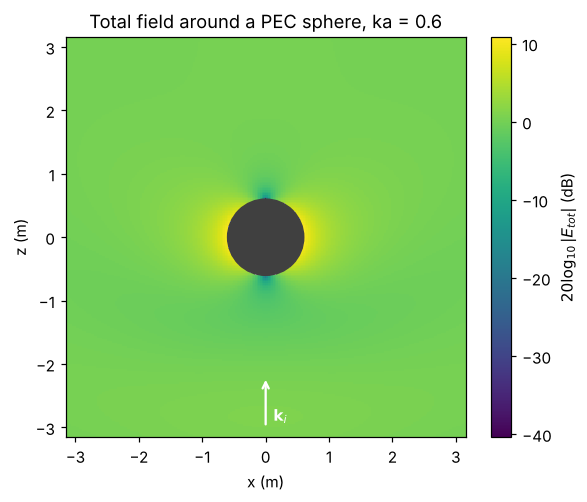

Peak |E_tot| on the map: 3.478
Surface field at theta = 90 deg for ka = 0.01: 3.00017 (static limit: 3)


In [7]:
ext = np.pi
xg, zg = np.meshgrid(np.linspace(-ext, ext, 241), np.linspace(-ext, ext, 241))
rg = np.hypot(xg, zg)
outside = rg > a_hw
th_g = np.arccos(np.clip(zg[outside] / rg[outside], -1, 1))
ph_g = np.where(xg[outside] >= 0, 0.0, np.pi)
E = fields(rg[outside], th_g, ph_g, k_hw, a_hw)
mag = np.full(xg.shape, np.nan)
mag[outside] = np.sqrt(sum(np.abs(c) ** 2 for c in E))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.pcolormesh(xg, zg, 20 * np.log10(mag), cmap="viridis", shading="auto")
ax.add_patch(plt.Circle((0, 0), a_hw, color="0.25"))
ax.annotate("", xy=(0, -2.2), xytext=(0, -3.0), arrowprops=dict(arrowstyle="->", color="w", lw=1.5))
ax.text(0.12, -2.9, "$\\mathbf{k}_i$", color="w")
fig.colorbar(im, ax=ax, label="$20\\log_{10}|E_{tot}|$ (dB)")
ax.set(xlabel="x (m)", ylabel="z (m)", title="Total field around a PEC sphere, ka = 0.6", aspect="equal")
ax.grid(False)
plt.tight_layout()
plt.show()
# Electrostatic limit: the peak surface field of a small conducting sphere approaches 3 E0
E_small = fields(0.01, np.pi / 2, 0.0, k=1.0, a=0.01)
assert abs(abs(E_small[0][0]) - 3) < 1e-3
print(f"Peak |E_tot| on the map: {np.nanmax(mag):.3f}")
print(f"Surface field at theta = 90 deg for ka = 0.01: {abs(E_small[0][0]):.5f} (static limit: 3)")

## References

- C. F. Bohren and D. R. Huffman, *Absorption and Scattering of Light by Small Particles*, Wiley, 1983, ch. 4.
- W. J. Wiscombe, "Improved Mie scattering algorithms," *Applied Optics*, vol. 19, no. 9, pp. 1505-1509, 1980.
- R. F. Harrington, *Time-Harmonic Electromagnetic Fields*, McGraw-Hill, 1961, sec. 6-9.
- E. F. Knott, J. F. Shaeffer, and M. T. Tuley, *Radar Cross Section*, 2nd ed., Artech House, 1993.